In [1]:
import sys
path='/home/tomas/Ulmer-Berechnung/alps2qutipplus-april/alps2qutipplus-main/'

sys.path.insert(1, path) 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qutip
import scipy.linalg as linalg

from alpsqutip import (build_system, list_models_in_alps_xml,
                       list_geometries_in_alps_xml, graph_from_alps_xml,
                       model_from_alps_xml,
                       restricted_maxent_toolkit as me)

from alpsqutip.operators.states.utils import safe_exp_and_normalize ## function used to safely and robustly map K-states to states
from alpsqutip.operators.states.meanfield import (one_body_from_qutip_operator, 
                                                  project_qutip_operator_as_n_body_operator)

from alpsqutip.scalarprod import fetch_covar_scalar_product, orthogonalize_basis

from alpsqutip.operators import (
    ScalarOperator,
    LocalOperator,
    OneBodyOperator,
    Operator,
    ProductOperator,
    ScalarOperator,
    SumOperator,
    QutipOperator
)

from alpsqutip.scalarprod import gram_matrix
from alpsqutip.operators.states.gibbs import GibbsDensityOperator

ImportError: cannot import name 'project_qutip_operator_as_n_body_operator' from 'alpsqutip.operators.states.meanfield' (/home/tomas/Ulmer-Berechnung/alps2qutipplus-april/alps2qutipplus-main/alpsqutip/operators/states/meanfield/__init__.py)

In [ ]:
params={}

params['size']=3
params['Jx']=1.; params['Jy'] = .75*params['Jx']; params['Jz']=1.05*params['Jx']

from scipy.optimize import root, fsolve
Ffactor=np.real(max(np.roots(np.poly1d([1, 0, -(params['Jx']*params['Jy']+params['Jx']*params['Jy']+params['Jy']*params['Jz']), 
                           -2*params['Jx']*params['Jy']*params['Jz']]))))
chi_y=fsolve(lambda x,y: x*np.arcsinh(x)-np.sqrt(x**2+1)-y, 1e-1, args=(0))[0]
vLR=4*Ffactor*chi_y

In [ ]:
system=build_system(geometry_name= "open chain lattice",model_name="spin", 
                    L=params['size'], J=1)

sites=[s for s in system.sites]
sx_ops=[system.site_operator("Sx", '1[' + str(a) + ']') for a in range(len(system.sites))]
sy_ops=[system.site_operator("Sy", '1[' + str(a) + ']') for a in range(len(system.sites))]
sz_ops=[system.site_operator("Sz", '1[' + str(a) + ']') for a in range(len(system.sites))]

Sz = system.global_operator("Sz")
H = (
    params['Jx'] * sum(sx_ops[i] * sx_ops[i+1] for i in range(len(sites)-1)) +
    params['Jy'] * sum(sy_ops[i] * sy_ops[i+1] for i in range(len(sites)-1)) +
    params['Jz'] * sum(sz_ops[i] * sz_ops[i+1] for i in range(len(sites)-1))
)

idop = [system.site_operator('identity@1[' + str(a) + ']') for a in range(len(system.sites))]
idop = idop[0]*idop[1]#*idop[2]#*idop[3]#*idop[4]*idop[5]*idop[6]

In [ ]:
HBB0=[idop, 
      system.site_operator('Sx', '1[0]'), 
      system.site_operator('Sy', '1[0]'), 
      system.site_operator('Sz', '1[0]')]

phi0 = np.array([.0, -.25, -.25, 
                 1])

K0 = me.k_state_from_phi_basis(phi0, HBB0)
sigma0 = GibbsDensityOperator(-K0)
phi0[0] = np.log(sigma0.tr())
K0 = me.k_state_from_phi_basis(phi0, HBB0)
sigma0 = GibbsDensityOperator(-K0)

[(sigma0 * op).tr() for op in sz_ops] 

In [ ]:
K0.to_qutip()

In [ ]:
ptrace_list=[i for i in range(0,3)]
obs_SzA=1/16*sum(sz for sz in sz_ops[0:3]).to_qutip().ptrace(ptrace_list)

timespan=np.linspace(.0, 650.1/vLR,45)

In [3]:
obs_SzA

NameError: name 'obs_SzA' is not defined

In [4]:
## exact dynamics
exact_K_at_timet=qutip.mesolve(H=H.to_qutip(), rho0=K0.to_qutip(), tlist=timespan)
exact_rho_at_timet=[safe_exp_and_normalize(K_at_timeti)[0] for K_at_timeti in exact_K_at_timet.states]

evs_obs_ex=[qutip.expect(rho_at_timeti.ptrace(ptrace_list), obs_SzA) for rho_at_timeti in exact_rho_at_timet]

NameError: name 'H' is not defined

In [108]:
Ktgt = K_local

Kop1=project_qutip_operator_as_n_body_operator(Ktgt.to_qutip_operator(), 
                                               nmax=1,
                                               sigma=sigma0)

In [109]:
simulations={}

In [112]:
simulations[1] = {
    "parms":{
    "chosen_depth": 7,
    "m0": 4,
    "eps": 1e-3,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[1]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [113]:
phi0_proj_act_MF = []; local_bound_error_ell=[]

simulations[1]["evs"] = [(sigma0.to_qutip().ptrace(ptrace_list)* obs_SzA).tr()]

sp_local=fetch_covar_scalar_product(sigma=sigma0); local_t_value=.0

HBB_ell_act = me.build_hierarchical_basis(generator=H,
                                          seed_op=K0,
                                          deep=chosen_depth)

orth_basis_act = orthogonalize_basis(basis=HBB_ell_act,
                                        sp = sp_local)

Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H, 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

phi0_proj_act = [sp_local(K0, op) for op in orth_basis_act]
phi_at_timet = [phi0_proj_act]  
K_at_timet = [K0]; K_act_at_timet=[K0]  
sigma_at_timet = [GibbsDensityOperator(-K0)]  

for t in timespan[1:]:
    print(t)
    phi_local=np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    K_local=me.k_state_from_phi_basis(phi=-phi_local,
                                      basis=orth_basis_act)
    sigma_local=GibbsDensityOperator(-K_local)
    phi_at_timet.append(phi_local)
    K_at_timet.append(K_local)
    
    simulations[1]["evs"].append((sigma_local.to_qutip().ptrace(ptrace_list)*obs_SzA).tr())  
    
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2) / me.m_th_partial_sum(phi=phi_local, m=0))
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        
        if list(timespan).index(t) % 50 == 0:  
            print("error", t)  
        
        local_t_value = t  
        
        print("a", list(timespan).index(t))
        K_act=project_qutip_operator_as_n_body_operator(operator=K_local.to_qutip_operator(),
                                         sigma=sigma_local, 
                                         nmax=1).to_qutip_operator()
        sigma_act=GibbsDensityOperator(-K_act)
        K_act_at_timet.append(K_act)        
        
        print("b")
        
        sp_local = fetch_covar_scalar_product(sigma=sigma_act)  
        HBB_ell_act = me.build_hierarchical_basis(generator=H,
                                                    seed_op=K_local.to_qutip_operator(), 
                                                    deep=chosen_depth)  

        print("c")
        
        HBB_ell_act= [project_qutip_operator_as_n_body_operator( operator = op.to_qutip_operator(), 
                                                nmax=m0,
                                                sigma=sigma_act) for op in HBB_ell_act]
        print("d")
        orth_basis_act = orthogonalize_basis(basis=HBB_ell_act, sp=sp_local)  
        
        Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H, 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

        
        print("e")
        
        phi0_proj_act = np.array([sp_local(K_local, op) for op in orth_basis_act] )
        phi0_proj_act_MF.append(phi0_proj_act)
        new_K_local=me.k_state_from_phi_basis(phi=-phi0_proj_act, basis=orth_basis_act)
        print("Fita", linalg.norm((new_K_local - K_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and 
        K_act_at_timet.append(K_local)

1.3745375068135424
2.7490750136270847
a 2
b
c
d
e
Fita 5.919374640526627e-05
4.123612520440627
5.4981500272541695
a 4
b
c
d
e
Fita 0.0
6.872687534067712
8.247225040881254
a 6
b
c
d
e
Fita 0.0
9.621762547694797
10.996300054508339
a 8
b
c
d
e
Fita 2.4839042386864533e-05
12.370837561321881
13.745375068135424
a 10
b
c
d
e
Fita 0.0
15.119912574948966
16.49445008176251
a 12
b
c
d
e
Fita 0.0
17.86898758857605
19.243525095389593
a 14
b
c
d
e
Fita 0.0
20.618062602203135
21.992600109016678
a 16
b
c
d
e
Fita 0.0
23.36713761583022
24.741675122643763
a 18
b
c
d
e
Fita 0.0
26.116212629457305
27.490750136270847
a 20
b
c
d
e
Fita 0.0
28.86528764308439
30.239825149897932
a 22
b
c
d
e
Fita 0.0
31.614362656711474
32.98890016352502
a 24
b
c
d
e
Fita 0.0
34.363437670338556
35.7379751771521
a 26
b
c
d
e
Fita 0.0
37.11251268396565
38.487050190779186
a 28
b
c
d
e
Fita 0.0
39.861587697592725
41.23612520440627
a 30
b
c
d
e
Fita 0.0
42.61066271121982
43.985200218033356
a 32
b
c
d
e
Fita 0.0
45.359737724846894
46

In [119]:
simulations[2] = {
    "parms":{
    "chosen_depth": 7,
    "m0": 2,
    "eps": 1e-3,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[2]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [120]:
phi0_proj_act_MF = []; local_bound_error_ell=[]

simulations[2]["evs"] = [(sigma0.to_qutip().ptrace(ptrace_list)* obs_SzA).tr()]

sp_local=fetch_covar_scalar_product(sigma=sigma0); local_t_value=.0

HBB_ell_act = me.build_hierarchical_basis(generator=H,
                                          seed_op=K0,
                                          deep=chosen_depth)

orth_basis_act = orthogonalize_basis(basis=HBB_ell_act,
                                        sp = sp_local)

Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H, 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

phi0_proj_act = [sp_local(K0, op) for op in orth_basis_act]
phi_at_timet = [phi0_proj_act]  
K_at_timet = [K0]; K_act_at_timet=[K0]  
sigma_at_timet = [GibbsDensityOperator(-K0)]  

for t in timespan[1:]:
    print(t)
    phi_local=np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    K_local=me.k_state_from_phi_basis(phi=-phi_local,
                                      basis=orth_basis_act)
    sigma_local=GibbsDensityOperator(-K_local)
    phi_at_timet.append(phi_local)
    K_at_timet.append(K_local)
    
    simulations[2]["evs"].append((sigma_local.to_qutip().ptrace(ptrace_list)*obs_SzA).tr())  
    
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2) / me.m_th_partial_sum(phi=phi_local, m=0))
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        
        if list(timespan).index(t) % 50 == 0:  
            print("error", t)  
        
        local_t_value = t  
        
        print("a", list(timespan).index(t))
        K_act=project_qutip_operator_as_n_body_operator(operator=K_local.to_qutip_operator(),
                                         sigma=sigma_local, 
                                         nmax=1).to_qutip_operator()
        sigma_act=GibbsDensityOperator(-K_act )
        K_act_at_timet.append(K_act )        
        
        print("b")
        
        sp_local = fetch_covar_scalar_product(sigma=sigma_act)  
        HBB_ell_act = me.build_hierarchical_basis(generator=H,
                                                    seed_op=K_local.to_qutip_operator(), 
                                                    deep=chosen_depth)  

        print("c")
        
        HBB_ell_act= [project_qutip_operator_as_n_body_operator( operator = op.to_qutip_operator(), 
                                                nmax=m0,
                                                sigma=sigma_act) for op in HBB_ell_act]
        print("d")
        orth_basis_act = orthogonalize_basis(basis=HBB_ell_act, sp=sp_local)  
        
        Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H, 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

        
        print("e")
        
        phi0_proj_act = np.array([sp_local(K_local, op) for op in orth_basis_act] )
        phi0_proj_act_MF.append(phi0_proj_act)
        new_K_local=me.k_state_from_phi_basis(phi=-phi0_proj_act, basis=orth_basis_act)
        print("Fita", linalg.norm((new_K_local - K_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and 
        K_act_at_timet.append(K_local)

1.3745375068135424
2.7490750136270847
a 2
b
c
d
e
Fita 0.8570534783099505
4.123612520440627
a 3
b
c
d
e
Fita 0.0
5.4981500272541695
a 4
b
c
d
e
Fita 3.8096808495460516e-12
6.872687534067712
a 5
b
c
d
e
Fita 0.0
8.247225040881254
a 6
b
c
d
e
Fita 1.5203371225673438e-11
9.621762547694797
10.996300054508339
a 8
b
c
d
e
Fita 5.2838693730963336e-11
12.370837561321881
a 9
b
c
d
e
Fita 2.4260214058316814e-11
13.745375068135424
a 10
b
c
d
e
Fita 1.7901977205931785e-11
15.119912574948966
a 11
b
c
d
e
Fita 5.5815952778193785e-11
16.49445008176251
a 12
b
c
d
e
Fita 3.9973812643919416e-11
17.86898758857605
a 13
b
c
d
e
Fita 1.1362632910561832e-10
19.243525095389593
a 14
b
c
d
e
Fita 5.6224112185544065e-11
20.618062602203135
a 15
b
c
d
e
Fita 4.4347340035849546e-11
21.992600109016678
a 16
b
c
d
e
Fita 6.98991392271127e-11
23.36713761583022
a 17
b
c
d
e
Fita 1.0667993971640355e-10
24.741675122643763
26.116212629457305
a 19
b
c
d
e
Fita 9.291178577940368e-11
27.490750136270847
a 20
b
c
d
e
Fita 5.734

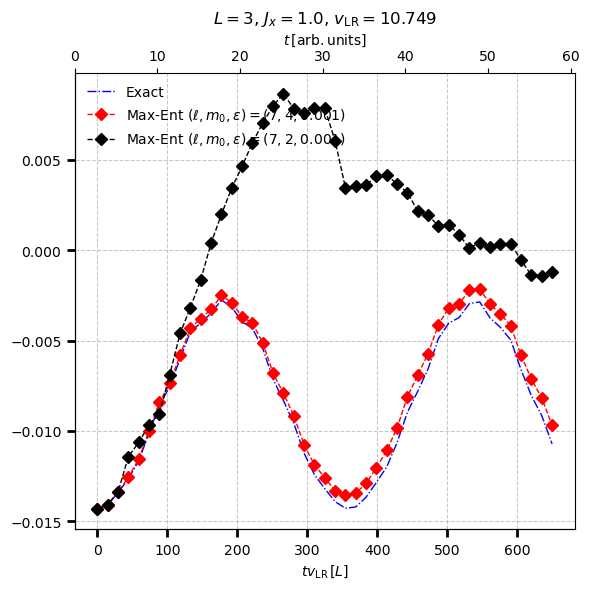

In [121]:
import matplotlib.pyplot as plt

# Création de la figure et des axes
fig, ax = plt.subplots(figsize=(6, 6))

n = 1

# Tracé de la courbe exacte
ax.plot(timespan * vLR, evs_obs_ex, label='Exact', color="blue", linestyle='dashdot', linewidth=1)

# Récupération des paramètres pour formater dynamiquement le label
l = simulations[1]["parms"]["chosen_depth"]
m0 = simulations[1]["parms"]["m0"]
eps = simulations[1]["parms"]["eps"]

label_sim1 = fr'Max-Ent $(\ell, m_0, \epsilon) = ({l}, {m0}, {eps})$'

l = simulations[2]["parms"]["chosen_depth"]
m0 = simulations[2]["parms"]["m0"]
eps = simulations[2]["parms"]["eps"]

label_sim2 = fr'Max-Ent $(\ell, m_0, \epsilon) = ({l}, {m0}, {eps})$'

# Tracé de la simulation 1
ax.plot(timespan * vLR, simulations[1]["evs"], 
        label=label_sim1, 
        color='red', linestyle='--', marker='D', linewidth=1)

# Tracé de la simulation courante
ax.plot(timespan * vLR, current_simulation["evs"], 
        label=label_sim2,  
        color='black', linestyle='--', marker='D', linewidth=1)

# Bordures uniquement à gauche et en bas (style minimaliste)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Personnalisation des ticks
ax.tick_params(direction='out', length=6, width=2, which='major', grid_alpha=0.6)
ax.grid(True, which='major', linestyle='--', linewidth=0.75, alpha=0.7)

ax.legend(frameon=False, loc='upper left')

# Axe secondaire
ax1 = ax.twiny()
ax1.set_xlim(timespan[0], timespan[-1])

# Étiquettes des axes
ax.set_xlabel(r'$t v_{\rm LR} \, [L]$')
ax1.set_xlabel(r'$t \, [{\rm arb. units}]$')

# Titre formaté avec LaTeX
plt.title(r'$L={}$, $J_x={}$, $v_{{\rm LR}}={}$'.format(
    params['size'], 
    round(params['Jx'], 3), 
    round(vLR, 3)
))

# Ajustement final
plt.tight_layout()


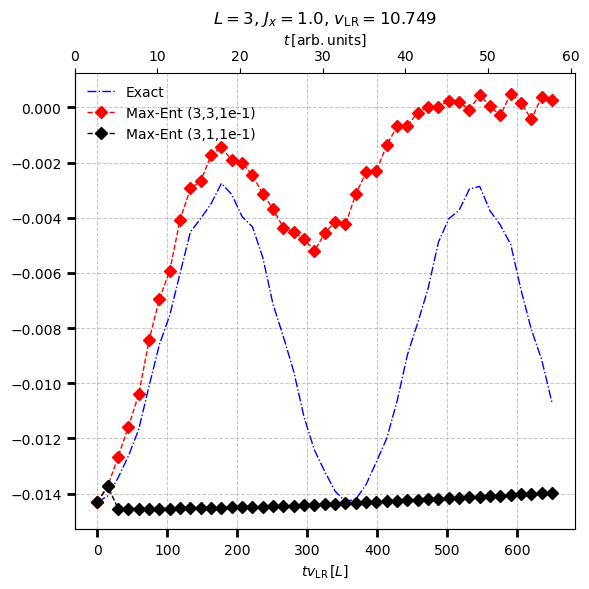

In [30]:
# Création de la figure et des axes
fig, ax = plt.subplots(figsize=(6, 6))

n=1
ax.plot(timespan * vLR, evs_obs_ex, label='Exact', color="blue", linestyle='dashdot', linewidth=1)
ax.plot(timespan * vLR, simulations[1]["evs"], label='Max-Ent (3,3,1e-1)', 
        color='red', linestyle='--', marker='D', linewidth=1)
ax.plot(timespan * vLR, current_simulation["evs"], label='Max-Ent (3,1,1e-1)', 
        color='black', linestyle='--', marker='D', linewidth=1)


# Bordures uniquement à gauche et en bas (style minimaliste)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Personnalisation des ticks
ax.tick_params(direction='out', length=6, width=2, which='major', grid_alpha=0.6)
ax.grid(True, which='major', linestyle='--', linewidth=0.75, alpha=0.7)

ax.legend(frameon=False, loc='upper left')

# Create a secondary x-axis (twinned) and set its limits
ax1 = ax.twiny()
ax1.set_xlim(timespan[0], timespan[-1])

# Set axis labels
ax.set_xlabel(r'$t v_{\rm LR} \, [L]$')
ax1.set_xlabel(r'$t \, [{\rm arb. units}]$')

# Format the title using the `params` dictionary values
# Ensure proper LaTeX formatting and consistent escape sequences
plt.title(r'$L={}$, $J_x={}$, $v_{{\rm LR}}={}$'.format(
    params['size'], 
    round(params['Jx'], 3), 
    round(vLR, 3)
))

# Adjustment final et affichage
plt.tight_layout()

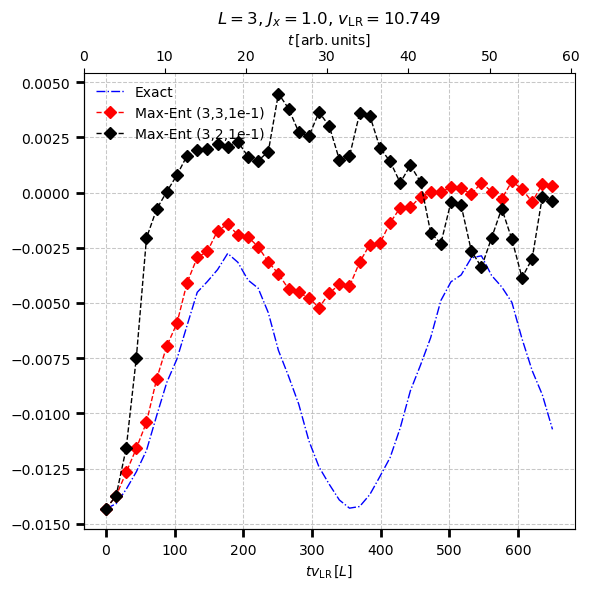

In [33]:
import matplotlib.pyplot as plt

# Création de la figure et des axes
fig, ax = plt.subplots(figsize=(6, 6))

n = 1

# Tracé de la courbe exacte
ax.plot(timespan * vLR, evs_obs_ex, label='Exact', color="blue", linestyle='dashdot', linewidth=1)

# Récupération des paramètres pour formater dynamiquement le label
l = simulations[1]["parms"]["chosen_depth"]
m0 = simulations[1]["parms"]["m0"]
eps = simulations[1]["parms"]["eps"]

label_sim1 = fr'Max-Ent $(\ell, m_0, \epsilon) = ({l}, {m0}, {eps})$'

# Tracé de la simulation 1
ax.plot(timespan * vLR, simulations[1]["evs"], 
        label=label_sim1, 
        color='red', linestyle='--', marker='D', linewidth=1)

# Tracé de la simulation courante
ax.plot(timespan * vLR, current_simulation["evs"], 
        label='Max-Ent (3,1,1e-1)', 
        color='black', linestyle='--', marker='D', linewidth=1)

# Bordures uniquement à gauche et en bas (style minimaliste)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Personnalisation des ticks
ax.tick_params(direction='out', length=6, width=2, which='major', grid_alpha=0.6)
ax.grid(True, which='major', linestyle='--', linewidth=0.75, alpha=0.7)

ax.legend(frameon=False, loc='upper left')

# Axe secondaire
ax1 = ax.twiny()
ax1.set_xlim(timespan[0], timespan[-1])

# Étiquettes des axes
ax.set_xlabel(r'$t v_{\rm LR} \, [L]$')
ax1.set_xlabel(r'$t \, [{\rm arb. units}]$')

# Titre formaté avec LaTeX
plt.title(r'$L={}$, $J_x={}$, $v_{{\rm LR}}={}$'.format(
    params['size'], 
    round(params['Jx'], 3), 
    round(vLR, 3)
))

# Ajustement final
plt.tight_layout()
